# Pillar 2 — Deposits and treasury (V1)

Scores all 387 U.S. MSAs on their capacity to produce **low-cost operating deposits** for a commercial, branch-light bank like BankUnited: deposit depth, payroll flows, household income and the incumbent banks' deposit mix.

**How to use**
1. Edit **`WEIGHTS`** and settings in section 2, then *Run All*. Weights are rescaled to 100%.
2. Section 3 documents every metric and why it matters.
3. Sections 6–8 show the scores, BankUnited's markets, a breakdown for one MSA, the HQ-booking sensitivity and diagnostics.

**Data:** only `data/processed/`. Deposits exclude bookings at main offices and home-banking offices (team decisions 10/6 and 10/26); the raw basis is a sensitivity in section 8.

**Output:** `outputs/pillar_scores/pillar2_scores.csv` and `pillar2_run.json`.

## 1. Setup

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "data" / "processed" / "msa_year.parquet").exists():
            return p
    raise FileNotFoundError("Run this notebook from inside the repo: data/processed/msa_year.parquet not found.")


ROOT = find_repo_root()
PROCESSED = ROOT / "data" / "processed"
msa_year = pd.read_parquet(PROCESSED / "msa_year.parquet")
bank_msa_year = pd.read_parquet(PROCESSED / "bank_msa_year.parquet")
bank_quarter = pd.read_parquet(PROCESSED / "bank_quarter.parquet")
bank_quarter["quarter_end"] = pd.to_datetime(bank_quarter["quarter_end"])

# Universe: the 387 metropolitan statistical areas in the 50 states and DC (Puerto Rico excluded),
# the same universe as Pillar 4.
universe = (msa_year.loc[~msa_year.cbsa_title.str.endswith(", PR"), ["cbsa_code", "cbsa_title"]]
            .drop_duplicates().sort_values("cbsa_code").set_index("cbsa_code"))
CBSAS = list(universe.index)
TITLE = universe.cbsa_title.to_dict()
N_MSA = len(CBSAS)
print(f"repo: {ROOT.name}")
print(f"msa_year {msa_year.shape}, bank_msa_year {bank_msa_year.shape}, bank_quarter {bank_quarter.shape}")
print(f"universe: {N_MSA} MSAs")

repo: bankunited-market-expansion-main
msa_year (3930, 56), bank_msa_year (331879, 21), bank_quarter (240330, 62)
universe: 387 MSAs


In [ ]:
def wide(col):
    """msa_year column as a CBSA x year table, restricted to the universe."""
    return msa_year.pivot(index="cbsa_code", columns="year", values=col).reindex(CBSAS)


def r12(s):
    return s.astype(float).round(12)


def cagr(start, end, years):
    """Compound annual growth; blank unless both ends exist and the start is positive."""
    ok = start.notna() & end.notna() & (start > 0)
    return r12((end / start) ** (1 / years) - 1).where(ok)


def ratio(num, den):
    """num / den; blank unless both exist and den is positive."""
    ok = num.notna() & den.notna() & (den > 0)
    return r12(num / den).where(ok)


def call(quarter_end):
    """Call Report values for one quarter, indexed by RSSD ID."""
    q = bank_quarter[bank_quarter.quarter_end == pd.Timestamp(quarter_end)].set_index("rssd_id")
    return q

def oriented_percentiles(metrics, directions):
    """Average-rank percentiles (0-100) among MSAs that have the metric; higher always = more attractive.
    Same rule as the Pillar 4 V2 workbook: 100 x (average oriented rank - 1) / (valid count - 1)."""
    P = pd.DataFrame(index=metrics.index)
    for col in metrics.columns:
        v = metrics[col] if directions[col] == "Higher" else -metrics[col]
        n = v.notna().sum()
        P[col] = 100 * (v.rank(method="average") - 1) / (n - 1) if n > 1 else np.nan
    return P


def score(metrics, directions, weights):
    """Available-data score (weights renormalized over the metrics an MSA has) and complete score
    (only when every metric is present). Ranks are among complete MSAs only."""
    w = pd.Series(weights, dtype=float)[list(metrics.columns)]
    P = oriented_percentiles(metrics, directions)
    have = P.notna()
    avail_w = have.mul(w, axis=1).sum(axis=1)
    available = P.fillna(0).mul(w, axis=1).sum(axis=1) / avail_w.where(avail_w > 0)
    complete = available.where(have.all(axis=1))
    out = pd.DataFrame({
        "msa": pd.Series(TITLE),
        "complete_score": complete,
        "rank": complete.rank(ascending=False, method="min"),
        "available_score": available,
        "valid_metrics": have.sum(axis=1),
        "weight_coverage": avail_w,
        "missing_metrics": have.apply(lambda r: ", ".join(c for c in r.index if not r[c]), axis=1),
    })
    contrib = P.mul(w, axis=1)            # weighted points per metric (sum = complete score)
    return out, P, contrib


def weight_rank_ranges(metrics, directions, weights, shock=0.25):
    """Best and worst complete rank when each weight alone moves +/- shock (then renormalized)."""
    base, _, _ = score(metrics, directions, weights)
    ranks = [base["rank"]]
    for k in weights:
        for s in (-shock, shock):
            w = dict(weights)
            w[k] = weights[k] * (1 + s)
            tot = sum(w.values())
            w = {kk: vv / tot for kk, vv in w.items()}
            ranks.append(score(metrics, directions, w)[0]["rank"])
    R = pd.concat(ranks, axis=1)
    return pd.DataFrame({"best_rank": R.min(axis=1), "worst_rank": R.max(axis=1)})


def check_weights(weights, registry):
    w = pd.Series(weights, dtype=float)
    unknown = sorted(set(w.index) - set(registry.index))
    assert not unknown, f"weights for unknown metrics: {unknown}"
    assert (w >= 0).all(), "weights must be zero or positive"
    unavailable = [k for k in w.index if registry.loc[k, "status"] == "not available" and w[k] > 0]
    used = w[[k for k in w.index if registry.loc[k, "status"] != "not available" and w[k] > 0]]
    assert len(used) > 0, "no weighted metric is available"
    eff = used / used.sum()
    if abs(w.sum() - 1) > 1e-9:
        print(f"Note: entered weights sum to {w.sum():.4f}; they are rescaled to 100%.")
    if unavailable:
        print("Weighted but NOT available in data/processed, so left out and the rest rescaled:",
              ", ".join(unavailable))
    return eff

def show_rank_table(results, metrics, n=25):
    cols = ["msa", "complete_score", "rank", "available_score", "valid_metrics"]
    t = results.sort_values(["complete_score", "available_score"], ascending=False)[cols].head(n)
    return t.round(2)

## 2. Weights and settings — edit here

Baseline: ten metrics at 10% each (V1).

In [ ]:
WEIGHTS = {
    # Deposit market (SOD, HQ bookings removed)
    "deposits_per_capita":   0.10,
    "deposit_growth":        0.10,
    "deposits_per_branch":   0.10,
    # Operating-deposit demand (CM-04)
    "wage_bill":             0.10,
    "wage_bill_growth":      0.10,
    "payroll_per_establishment": 0.10,
    # Household deposit base
    "income_per_capita":     0.10,
    "income_growth":         0.10,
    # Incumbent deposit franchise (CM-01)
    "incumbent_nib_share":   0.10,
    "incumbent_uninsured_share": 0.10,
}

SETTINGS = {
    "sod_start": 2019, "sod_end": 2024,          # SOD June 30 surveys
    "call_quarter": "2024-06-30",                # matches the SOD date
    "qcew_start": 2019, "qcew_end": 2024,
    "bea_start": 2019, "bea_end": 2024,
    "cbp_year": 2023,
    "exclude_home_banking_offices": True,        # 10/26 decision: treat like main-office bookings
    "min_call_coverage": 0.50,                   # share of an MSA's deposits that must match a Call Report
}
EXAMPLE_CBSA = "16740"
PILLAR_TAG = "pillar2"

## 3. Metric dictionary

| # | Metric | Group | Definition | Why it matters for BankUnited | Status |
|---|---|---|---|---|---|
| 1 | Deposits per capita | Deposit market | SOD deposits minus main-office and home-banking-office bookings, June 2024, per resident | Depth of the local deposit pool without national bookings (Charlotte, Sioux Falls, Wilmington) inflating it. | Available |
| 2 | Deposit growth | Deposit market | 2019–24 CAGR of the same deposits | Growing deposit pools are easier for a new entrant to take share in. | Available |
| 3 | Deposits per branch | Deposit market | Same deposits ÷ full-service branches excluding main offices | High means deposits can be gathered without a dense branch network, matching a commercial-first, branch-light entry. | Available |
| 4 | Wage bill | Operating-deposit demand | QCEW total wages, 2024 | Payrolls run through operating accounts; this is the pillar's scale measure of treasury-management demand. | Available |
| 5 | Wage bill growth | Operating-deposit demand | 2019–24 CAGR of QCEW wages | Growth in operating flows that a commercial bank can capture. | Available |
| 6 | Payroll per establishment | Operating-deposit demand | CBP 2023 payroll ÷ establishments | Larger firms carry larger operating balances and need treasury services. | Available |
| 7 | Income per capita | Household deposit base | BEA personal income 2024 ÷ PEP population | Affluent markets hold more deposits per resident, including business owners' personal accounts. | Available |
| 8 | Income growth | Household deposit base | 2019–24 CAGR of BEA personal income | Rising income grows the deposit base over time. | Available |
| 9 | Incumbent NIB share | Incumbent franchise | Each bank's non-interest-bearing ÷ total deposits (Call Report), weighted by its local non-HQ deposits | A market whose deposits sit in operating accounts offers the cheap funding BankUnited's model seeks. | Available (bank-wide ratios) |
| 10 | Incumbent uninsured share | Incumbent franchise | Each bank's uninsured ÷ total deposits, weighted the same way | Large uninsured balances signal commercial clients; they are also less sticky (direction to confirm). | Available (reported uninsured for $1B+ banks; 1 − insured share otherwise) |

In [ ]:
REGISTRY = pd.DataFrame([
    ("deposits_per_capita", "Deposits per capita (ex-HQ)", "Deposit market", "Higher", "June 2024", "msa_year.sod_* + pep", "available"),
    ("deposit_growth", "Deposit growth (ex-HQ)", "Deposit market", "Higher", "2019–24 CAGR", "msa_year.sod_*", "available"),
    ("deposits_per_branch", "Deposits per non-HQ branch", "Deposit market", "Higher", "June 2024", "msa_year.sod_* + bank_msa_year", "available"),
    ("wage_bill", "Total wage bill", "Operating-deposit demand", "Higher", "2024", "msa_year.bls_qcew_total_wages_usd", "available"),
    ("wage_bill_growth", "Wage bill growth", "Operating-deposit demand", "Higher", "2019–24 CAGR", "msa_year.bls_qcew_total_wages_usd", "available"),
    ("payroll_per_establishment", "Payroll per establishment", "Operating-deposit demand", "Higher", "2023", "msa_year.cbp_*", "available"),
    ("income_per_capita", "Personal income per capita", "Household deposit base", "Higher", "2024", "msa_year.bea_* + pep", "available"),
    ("income_growth", "Personal income growth", "Household deposit base", "Higher", "2019–24 CAGR", "msa_year.bea_personal_income_usd", "available"),
    ("incumbent_nib_share", "Incumbent non-interest-bearing share", "Incumbent franchise", "Higher", "June 2024", "bank_quarter × bank_msa_year", "available"),
    ("incumbent_uninsured_share", "Incumbent uninsured share", "Incumbent franchise", "Higher", "June 2024", "bank_quarter × bank_msa_year", "available"),
], columns=["key", "label", "group", "direction", "period", "source", "status"]).set_index("key")

EFFECTIVE = check_weights(WEIGHTS, REGISTRY)
ACTIVE = list(EFFECTIVE.index)
DIRECTIONS = REGISTRY.direction.to_dict()
REGISTRY["entered_weight"] = pd.Series(WEIGHTS)
REGISTRY["effective_weight"] = EFFECTIVE
REGISTRY.assign(entered_weight=REGISTRY.entered_weight.map("{:.1%}".format),
                effective_weight=REGISTRY.effective_weight.map(lambda v: "—" if pd.isna(v) else f"{v:.1%}"))

,label,group,direction,period,source,status,entered_weight,effective_weight
key,,,,,,,,
deposits_per_capita,Deposits per capita (ex-HQ),Deposit market,Higher,June 2024,msa_year.sod_* + pep,available,10.0%,10.0%
deposit_growth,Deposit growth (ex-HQ),Deposit market,Higher,2019–24 CAGR,msa_year.sod_*,available,10.0%,10.0%
deposits_per_branch,Deposits per non-HQ branch,Deposit market,Higher,June 2024,msa_year.sod_* + bank_msa_year,available,10.0%,10.0%
wage_bill,Total wage bill,Operating-deposit demand,Higher,2024,msa_year.bls_qcew_total_wages_usd,available,10.0%,10.0%
wage_bill_growth,Wage bill growth,Operating-deposit demand,Higher,2019–24 CAGR,msa_year.bls_qcew_total_wages_usd,available,10.0%,10.0%
payroll_per_establishment,Payroll per establishment,Operating-deposit demand,Higher,2023,msa_year.cbp_*,available,10.0%,10.0%
income_per_capita,Personal income per capita,Household deposit base,Higher,2024,msa_year.bea_* + pep,available,10.0%,10.0%
income_growth,Personal income growth,Household deposit base,Higher,2019–24 CAGR,msa_year.bea_personal_income_usd,available,10.0%,10.0%
incumbent_nib_share,Incumbent non-interest-bearing share,Incumbent franchise,Higher,June 2024,bank_quarter × bank_msa_year,available,10.0%,10.0%


## 4. Data availability check

In [ ]:
NEEDED = {
    "msa_year": ["sod_deposits_usd", "sod_main_office_deposits_usd", "sod_home_banking_office_deposits_usd",
                 "sod_branches_count", "pep_population_count", "bls_qcew_total_wages_usd", "cbp_annual_payroll_usd",
                 "cbp_establishments_count", "bea_personal_income_usd"],
    "bank_msa_year": ["sod_deposits_usd", "sod_main_office_deposits_usd", "sod_home_banking_office_deposits_usd"],
    "bank_quarter": ["call_total_deposits_usd", "call_noninterest_bearing_deposits_usd", "call_uninsured_deposits_usd",
                     "call_insured_deposits_usd_net"],
}
tables = {"msa_year": msa_year, "bank_msa_year": bank_msa_year, "bank_quarter": bank_quarter}
avail = pd.DataFrame([(t, c, c in tables[t].columns) for t, cols in NEEDED.items() for c in cols],
                     columns=["table", "column", "present"])
assert avail.present.all(), avail[~avail.present]
print("All required columns present. Every Pillar 2 metric can be built from data/processed.")
NOT_AVAILABLE = pd.DataFrame([
    ("Deposit pricing (cost of deposits, betas)", "Call Report interest expense is not in bank_quarter", "Not scored; add RIAD4073 to ingest_ffiec.py to score it"),
    ("Home-banking offices in the branch count", "Branch counts don't flag home-banking offices", "Deposits exclude them; the branch denominator still counts them"),
], columns=["gap", "detail", "effect"])
NOT_AVAILABLE

All required columns present. Every Pillar 2 metric can be built from data/processed.


,gap,detail,effect
0,"Deposit pricing (cost of deposits, betas)",Call Report interest expense is not in bank_quarter,Not scored; add RIAD4073 to ingest_ffiec.py to score it
1,Home-banking offices in the branch count,Branch counts don't flag home-banking offices,Deposits exclude them; the branch denominator still counts them


## 5. Build the metrics

### 5a. Deposit market (SOD, HQ bookings removed)

In [ ]:
d0, d1 = SETTINGS["sod_start"], SETTINGS["sod_end"]
dep = wide("sod_deposits_usd")
booked = wide("sod_main_office_deposits_usd").fillna(0)
if SETTINGS["exclude_home_banking_offices"]:
    booked = booked + wide("sod_home_banking_office_deposits_usd").fillna(0)
local_dep = (dep - booked).where(dep.notna())
pop = wide("pep_population_count")

# main offices in each MSA (a bank-MSA row with main-office deposits), to take them out of the branch count
bm = bank_msa_year[(bank_msa_year.year == d1) & bank_msa_year.sod_deposits_usd.notna()]
main_offices = bm[bm.sod_main_office_deposits_usd.fillna(0) > 0].groupby("cbsa_code").size().reindex(CBSAS).fillna(0)
branches = wide("sod_branches_count")[d1]
local_branches = (branches - main_offices).where(lambda b: b > 0, branches)

metrics = pd.DataFrame(index=CBSAS)
metrics["deposits_per_capita"] = ratio(local_dep[d1], pop[d1])
metrics["deposit_growth"] = cagr(local_dep[d0], local_dep[d1], d1 - d0)
metrics["deposits_per_branch"] = ratio(local_dep[d1], local_branches)

### 5b. Operating-deposit demand and 5c. household deposit base

In [ ]:
q0, q1 = SETTINGS["qcew_start"], SETTINGS["qcew_end"]
wages = wide("bls_qcew_total_wages_usd")
metrics["wage_bill"] = wages[q1]
metrics["wage_bill_growth"] = cagr(wages[q0], wages[q1], q1 - q0)
cy = SETTINGS["cbp_year"]
metrics["payroll_per_establishment"] = ratio(wide("cbp_annual_payroll_usd")[cy], wide("cbp_establishments_count")[cy])

b0, b1 = SETTINGS["bea_start"], SETTINGS["bea_end"]
income = wide("bea_personal_income_usd")
metrics["income_per_capita"] = ratio(income[b1], pop[b1])
metrics["income_growth"] = cagr(income[b0], income[b1], b1 - b0)

### 5d. Incumbent deposit franchise (CM-01)
Each bank's bank-wide Call Report ratios, weighted by its local (non-HQ) deposits in the MSA. Uninsured share uses reported uninsured deposits (RCON5597, filed by banks with $1B+ in assets) and falls back to 1 − estimated insured ÷ total for smaller banks.

In [ ]:
c = call(SETTINGS["call_quarter"])
tot = c.call_total_deposits_usd.where(c.call_total_deposits_usd > 0)
nib = r12(c.call_noninterest_bearing_deposits_usd / tot)
unins = (c.call_uninsured_deposits_usd / tot).where(c.call_uninsured_deposits_usd.notna(),
                                                   1 - c.call_insured_deposits_usd_net / tot).clip(0, 1)


def incumbent_shares(local_basis=True):
    b = bank_msa_year[(bank_msa_year.year == d1) & bank_msa_year.sod_deposits_usd.notna() & bank_msa_year.cbsa_code.isin(CBSAS)].copy()
    w = b.sod_deposits_usd
    if local_basis:
        w = w - b.sod_main_office_deposits_usd.fillna(0)
        if SETTINGS["exclude_home_banking_offices"]:
            w = w - b.sod_home_banking_office_deposits_usd.fillna(0)
    b["w"] = w.clip(lower=0)
    b["nib"], b["unins"] = b.rssd_id.map(nib), b.rssd_id.map(unins)
    g = b.assign(w_nib=b.w.where(b.nib.notna(), 0), x_nib=b.w * b.nib.fillna(0),
                 w_un=b.w.where(b.unins.notna(), 0), x_un=b.w * b.unins.fillna(0)).groupby("cbsa_code")
    S = pd.DataFrame({k: g[k].sum() for k in ["w", "w_nib", "x_nib", "w_un", "x_un"]}).reindex(CBSAS)
    ok_nib = (S.w_nib > 0) & (S.w_nib / S.w >= SETTINGS["min_call_coverage"])
    ok_un = (S.w_un > 0) & (S.w_un / S.w >= SETTINGS["min_call_coverage"])
    return r12(S.x_nib / S.w_nib).where(ok_nib), r12(S.x_un / S.w_un).where(ok_un)


metrics["incumbent_nib_share"], metrics["incumbent_uninsured_share"] = incumbent_shares(local_basis=True)
metrics = metrics[list(REGISTRY.index)]
pd.DataFrame({"label": REGISTRY.label, "MSAs with a value": metrics.notna().sum(), "median": metrics.median().round(4)})

,label,MSAs with a value,median
deposits_per_capita,Deposits per capita (ex-HQ),387,"21,492.4438"
deposit_growth,Deposit growth (ex-HQ),382,0.0582
deposits_per_branch,Deposits per non-HQ branch,387,"103,127,367.6471"
wage_bill,Total wage bill,387,"6,507,053,304.0000"
wage_bill_growth,Wage bill growth,382,0.0528
payroll_per_establishment,Payroll per establishment,387,"856,389.4951"
income_per_capita,Personal income per capita,387,"61,766.6325"
income_growth,Personal income growth,382,0.0595
incumbent_nib_share,Incumbent non-interest-bearing share,387,0.2537
incumbent_uninsured_share,Incumbent uninsured share,387,0.3849


In [ ]:
FMT_PCT = lambda v: "—" if pd.isna(v) else f"{v:.2%}"
FMT_USD = lambda v: "—" if pd.isna(v) else f"${v:,.0f}"
FORMAT = {k: FMT_PCT for k in REGISTRY.index}
for k in ("deposits_per_capita", "deposits_per_branch", "wage_bill", "payroll_per_establishment", "income_per_capita"):
    FORMAT[k] = FMT_USD
metrics.join(pd.Series(TITLE, name="msa")).set_index("msa", append=True).loc[:, ACTIVE].head(10)

,,deposits_per_capita,deposit_growth,deposits_per_branch,wage_bill,wage_bill_growth,payroll_per_establishment,income_per_capita,income_growth,incumbent_nib_share,incumbent_uninsured_share
,msa,,,,,,,,,,
10180,"Abilene, TX","15,627.6270",0.0691,"71,777,300.0000","4,128,261,214.0000",0.0611,"753,898.6341","59,102.0254",0.0658,0.3004,0.3673
10420,"Akron, OH","25,812.4564",0.0462,"117,354,824.6753","19,674,086,742.0000",0.0416,"1,047,548.5941","65,959.2231",0.0522,0.2181,0.3796
10500,"Albany, GA","16,169.5732",0.0548,"87,260,000.0000","3,065,751,792.0000",0.0420,"688,658.6384","50,530.2216",0.0535,0.2668,0.4034
10540,"Albany, OR","10,414.2355",0.0505,"69,038,050.0000","2,791,528,153.0000",0.0522,"703,779.3394","59,926.7332",0.0704,0.2686,0.4100
10580,"Albany-Schenectady-Troy, NY","30,150.8702",-0.0089,"108,202,688.9764","34,741,858,629.0000",0.0614,"1,105,497.9230","76,722.7569",0.0593,0.2144,0.3912
10740,"Albuquerque, NM","21,256.5064",0.0647,"146,674,335.8209","25,244,809,130.0000",0.0643,"891,963.5877","61,009.0815",0.0673,0.2597,0.4224
10780,"Alexandria, LA","16,144.4107",0.0709,"45,095,603.7736","3,111,867,161.0000",0.0447,"710,848.9614","56,149.5511",0.0452,0.2431,0.3303
10900,"Allentown-Bethlehem-Easton, PA-NJ","22,526.0378",0.0504,"111,265,664.8045","24,295,030,048.0000",0.0487,"1,163,153.1469","67,737.5670",0.0488,0.2391,0.3818
11020,"Altoona, PA","28,269.1606",0.0664,"80,803,357.1429","3,090,740,314.0000",0.0418,"871,213.3417","60,307.2361",0.0482,0.2606,0.3574


## 6. Score

Each metric becomes a percentile (0–100) among the MSAs that have it, oriented so higher is always more attractive. The **complete score** is the weighted average of the percentiles and needs every weighted metric. The **available-data score** renormalizes the weights over the metrics an MSA has, so MSAs with gaps still get a provisional number. Ranks are among complete MSAs only. This is the same method as the Pillar 4 V2 workbook.

In [ ]:
results, P, contrib = score(metrics[ACTIVE], DIRECTIONS, EFFECTIVE.to_dict())
n_complete = int(results["rank"].notna().sum())
print(f"{n_complete} complete, {N_MSA - n_complete} partial")
print(results.loc[results["rank"].isna(), "missing_metrics"].value_counts().head(5).to_string())

382 complete, 5 partial
missing_metrics
deposit_growth, wage_bill_growth, income_growth    5


In [ ]:
show_rank_table(results, metrics, n=25)

,msa,complete_score,rank,available_score,valid_metrics
41940,"San Jose-Sunnyvale-Santa Clara, CA",89.1300,1.0000,89.1300,10
12420,"Austin-Round Rock-San Marcos, TX",88.7200,2.0000,88.7200,10
19100,"Dallas-Fort Worth-Arlington, TX",86.3700,3.0000,86.3700,10
38060,"Phoenix-Mesa-Chandler, AZ",85.1800,4.0000,85.1800,10
41620,"Salt Lake City-Murray, UT",84.8300,5.0000,84.8300,10
27260,"Jacksonville, FL",83.6500,6.0000,83.6500,10
12060,"Atlanta-Sandy Springs-Roswell, GA",82.9200,7.0000,82.9200,10
34980,"Nashville-Davidson--Murfreesboro--Franklin, TN",81.8700,8.0000,81.8700,10
39580,"Raleigh-Cary, NC",80.9600,9.0000,80.9600,10
26420,"Houston-Pasadena-The Woodlands, TX",79.9300,10.0000,79.9300,10


## 7. BankUnited's markets and an example MSA

In [ ]:
# BankUnited's markets. Branch markets come from the data (msa_year.bankunited_sod_offices_count, June 2024).
# Markets it serves from offices without branches are not visible in SOD; they come from src/bankunited.py
# (Atlanta office opened 2022-04-07) and the project work order (Charlotte entry July 2025; Houston office).
bu_branch = msa_year[(msa_year.year == 2024) & (msa_year.bankunited_sod_offices_count > 0)].cbsa_code.tolist()
BU_OFFICE_ONLY = {"12060": "Atlanta office", "16740": "Charlotte (entered Jul 2025)", "26420": "Houston office"}
bu_markets = pd.DataFrame({"cbsa_code": bu_branch + [c for c in BU_OFFICE_ONLY if c not in bu_branch]})
bu_markets["presence"] = ["SOD branch" if c in bu_branch else BU_OFFICE_ONLY[c] for c in bu_markets.cbsa_code]
bu_markets = bu_markets.set_index("cbsa_code").join(results[["msa", "complete_score", "rank", "available_score"]])
bu_markets.sort_values("rank").round(2)

,presence,msa,complete_score,rank,available_score
cbsa_code,,,,,
19100,SOD branch,"Dallas-Fort Worth-Arlington, TX",86.3700,3.0000,86.3700
12060,Atlanta office,"Atlanta-Sandy Springs-Roswell, GA",82.9200,7.0000,82.9200
26420,Houston office,"Houston-Pasadena-The Woodlands, TX",79.9300,10.0000,79.9300
33100,SOD branch,"Miami-Fort Lauderdale-West Palm Beach, FL",77.8700,15.0000,77.8700
16740,Charlotte (entered Jul 2025),"Charlotte-Concord-Gastonia, NC-SC",75.3200,20.0000,75.3200
45300,SOD branch,"Tampa-St. Petersburg-Clearwater, FL",73.4400,23.0000,73.4400
36740,SOD branch,"Orlando-Kissimmee-Sanford, FL",73.1700,24.0000,73.1700
35840,SOD branch,"North Port-Bradenton-Sarasota, FL",71.3800,37.0000,71.3800
35620,SOD branch,"New York-Newark-Jersey City, NY-NJ",69.4600,42.0000,69.4600


Charlotte-Concord-Gastonia, NC-SC: complete score 75.32, rank 20 of 382


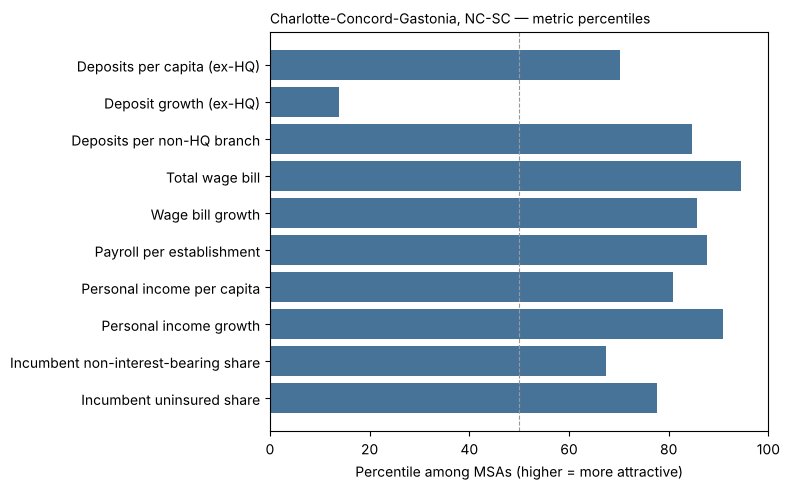

,metric,raw value,percentile,weight,points
deposits_per_capita,Deposits per capita (ex-HQ),"$25,457",70.2000,10.0%,7.0200
deposit_growth,Deposit growth (ex-HQ),3.73%,13.9000,10.0%,1.3900
deposits_per_branch,Deposits per non-HQ branch,"$153,630,477",84.7000,10.0%,8.4700
wage_bill,Total wage bill,"$102,059,764,278",94.6000,10.0%,9.4600
wage_bill_growth,Wage bill growth,7.18%,85.6000,10.0%,8.5600
payroll_per_establishment,Payroll per establishment,"$1,190,488",87.6000,10.0%,8.7600
income_per_capita,Personal income per capita,"$73,109",80.8000,10.0%,8.0800
income_growth,Personal income growth,8.04%,90.8000,10.0%,9.0800
incumbent_nib_share,Incumbent non-interest-bearing share,26.92%,67.4000,10.0%,6.7400
incumbent_uninsured_share,Incumbent uninsured share,40.71%,77.7000,10.0%,7.7700


In [ ]:
ex = EXAMPLE_CBSA
breakdown = pd.DataFrame({
    "metric": REGISTRY.loc[ACTIVE, "label"],
    "raw value": [FORMAT[k](metrics.loc[ex, k]) for k in ACTIVE],
    "percentile": P.loc[ex, ACTIVE].round(1),
    "weight": [f"{EFFECTIVE[k]:.1%}" for k in ACTIVE],
    "points": contrib.loc[ex, ACTIVE].round(2),
})
print(f"{TITLE[ex]}: complete score {results.loc[ex, 'complete_score']:.2f}, rank {results.loc[ex, 'rank']:.0f} of "
      f"{int(results['rank'].notna().sum())}")
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(ACTIVE) + 1))
    b = breakdown.iloc[::-1]
    ax.barh(b["metric"], b["percentile"], color="#477399")
    ax.axvline(50, color="#999", lw=0.8, ls="--")
    ax.set_xlim(0, 100); ax.set_xlabel("Percentile among MSAs (higher = more attractive)")
    ax.set_title(f"{TITLE[ex]} — metric percentiles", loc="left", fontsize=10)
    plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib not installed; table only.")
breakdown

## 8. HQ-booking sensitivity and diagnostics

Rescore with main-office and home-banking bookings kept in (raw SOD deposits), to see which MSAs depend on the rule.

In [ ]:
raw = metrics.copy()
raw["deposits_per_capita"] = ratio(dep[d1], pop[d1])
raw["deposit_growth"] = cagr(dep[d0], dep[d1], d1 - d0)
raw["deposits_per_branch"] = ratio(dep[d1], branches)
raw["incumbent_nib_share"], raw["incumbent_uninsured_share"] = incumbent_shares(local_basis=False)
raw_results, _, _ = score(raw[ACTIVE], DIRECTIONS, EFFECTIVE.to_dict())
cmp_ = results[["msa", "complete_score", "rank"]].join(raw_results[["complete_score", "rank"]], rsuffix="_raw")
cmp_["score_change"] = cmp_.complete_score - cmp_.complete_score_raw
moved = cmp_[cmp_.score_change.abs() > 10]
print(f"{len(moved)} MSAs move more than 10 points when HQ bookings are kept in.")
cmp_.reindex(cmp_.score_change.abs().sort_values(ascending=False).index).head(12).round(2)

13 MSAs move more than 10 points when HQ bookings are kept in.


,msa,complete_score,rank,complete_score_raw,rank_raw,score_change
21420,"Enid, OK",17.3200,380.0000,42.1800,261.0000,-24.8600
28140,"Kansas City, MO-KS",53.6200,152.0000,75.0600,16.0000,-21.4400
29820,"Las Vegas-Henderson-North Las Vegas, NV",79.7100,11.0000,62.8300,78.0000,16.8800
24580,"Green Bay, WI",45.1000,240.0000,61.3900,90.0000,-16.2900
17410,"Cleveland, OH",53.8200,149.0000,69.3200,43.0000,-15.5000
48660,"Wichita Falls, TX",26.0500,358.0000,40.9500,274.0000,-14.9000
43620,"Sioux Falls, SD-MN",59.3400,106.0000,73.7500,22.0000,-14.4100
16740,"Charlotte-Concord-Gastonia, NC-SC",75.3200,20.0000,88.8300,1.0000,-13.5000
30700,"Lincoln, NE",44.2800,249.0000,57.4100,121.0000,-13.1300
29700,"Laredo, TX",36.9800,295.0000,48.9400,188.0000,-11.9600


In [ ]:
# Redundancy check: Spearman correlation between metrics. Pairs above ~0.8 measure nearly the same thing,
# so together they carry double weight.
corr = metrics[ACTIVE].corr(method="spearman").round(2)
high = [(a, b, corr.loc[a, b]) for i, a in enumerate(ACTIVE) for b in ACTIVE[i + 1:] if abs(corr.loc[a, b]) >= 0.8]
print("Highly correlated pairs (|rho| >= 0.8):", high or "none")
corr

Highly correlated pairs (|rho| >= 0.8): none


,deposits_per_capita,deposit_growth,deposits_per_branch,wage_bill,wage_bill_growth,payroll_per_establishment,income_per_capita,income_growth,incumbent_nib_share,incumbent_uninsured_share
deposits_per_capita,1.0000,0.1300,0.5100,0.4400,0.0500,0.3000,0.6500,0.0800,-0.2000,-0.0000
deposit_growth,0.1300,1.0000,0.0400,-0.0200,0.3300,-0.0400,-0.1100,0.3100,-0.0000,-0.0800
deposits_per_branch,0.5100,0.0400,1.0000,0.5700,0.2500,0.2200,0.5200,0.2800,0.2500,0.5300
wage_bill,0.4400,-0.0200,0.5700,1.0000,0.1700,0.5800,0.5500,0.2300,0.0000,0.3600
wage_bill_growth,0.0500,0.3300,0.2500,0.1700,1.0000,-0.2400,0.1300,0.7800,0.2800,0.1800
payroll_per_establishment,0.3000,-0.0400,0.2200,0.5800,-0.2400,1.0000,0.3500,-0.1700,-0.2800,0.1000
income_per_capita,0.6500,-0.1100,0.5200,0.5500,0.1300,0.3500,1.0000,0.1900,-0.1200,0.1400
income_growth,0.0800,0.3100,0.2800,0.2300,0.7800,-0.1700,0.1900,1.0000,0.2500,0.1800
incumbent_nib_share,-0.2000,-0.0000,0.2500,0.0000,0.2800,-0.2800,-0.1200,0.2500,1.0000,0.3500
incumbent_uninsured_share,-0.0000,-0.0800,0.5300,0.3600,0.1800,0.1000,0.1400,0.1800,0.3500,1.0000


In [ ]:
# Weight sensitivity: best and worst rank when each weight alone moves +/-25% (as in the workbook).
rr = weight_rank_ranges(metrics[ACTIVE], DIRECTIONS, EFFECTIVE.to_dict(), shock=0.25)
top = results.sort_values("rank").head(25).join(rr)
top[["msa", "complete_score", "rank", "best_rank", "worst_rank"]].round(2)

,msa,complete_score,rank,best_rank,worst_rank
41940,"San Jose-Sunnyvale-Santa Clara, CA",89.1300,1.0000,1.0000,2.0000
12420,"Austin-Round Rock-San Marcos, TX",88.7200,2.0000,1.0000,2.0000
19100,"Dallas-Fort Worth-Arlington, TX",86.3700,3.0000,3.0000,4.0000
38060,"Phoenix-Mesa-Chandler, AZ",85.1800,4.0000,4.0000,5.0000
41620,"Salt Lake City-Murray, UT",84.8300,5.0000,3.0000,6.0000
27260,"Jacksonville, FL",83.6500,6.0000,5.0000,7.0000
12060,"Atlanta-Sandy Springs-Roswell, GA",82.9200,7.0000,6.0000,7.0000
34980,"Nashville-Davidson--Murfreesboro--Franklin, TN",81.8700,8.0000,8.0000,8.0000
39580,"Raleigh-Cary, NC",80.9600,9.0000,9.0000,10.0000
26420,"Houston-Pasadena-The Woodlands, TX",79.9300,10.0000,9.0000,13.0000


## 9. Export

In [ ]:
out_dir = ROOT / "outputs" / "pillar_scores"
out_dir.mkdir(parents=True, exist_ok=True)
table = (results.join(metrics[ACTIVE].add_prefix("raw_")).join(P[ACTIVE].add_prefix("pct_"))
         .sort_values(["complete_score", "available_score"], ascending=False))
table.rename_axis("cbsa_code").to_csv(out_dir / f"{PILLAR_TAG}_scores.csv")
run = {"pillar": PILLAR_TAG, "run_date": str(pd.Timestamp.today().date()), "effective_weights": EFFECTIVE.round(6).to_dict(),
       "entered_weights": WEIGHTS, "settings": SETTINGS, "complete_msas": int(results["rank"].notna().sum()),
       "not_available": REGISTRY.index[REGISTRY.status == "not available"].tolist()}
(out_dir / f"{PILLAR_TAG}_run.json").write_text(json.dumps(run, indent=2))
print("wrote", (out_dir / f"{PILLAR_TAG}_scores.csv").relative_to(ROOT), "and", (out_dir / f"{PILLAR_TAG}_run.json").relative_to(ROOT))

wrote outputs/pillar_scores/pillar2_scores.csv and outputs/pillar_scores/pillar2_run.json


## Notes and limits
- **Incumbent ratios are bank-wide.** A national bank's NIB and uninsured shares are applied to its local deposits; the measure describes who holds the market's deposits, not local account mix.
- **Uninsured share cuts both ways.** It signals commercial balances but also flight risk; the direction is a proposal to confirm.
- **Deposit pricing is not scored**: interest expense is not in `bank_quarter`.
- **Connecticut** lacks 2019 SOD, QCEW and BEA values (old county codes), so its five MSAs are partial.
- **Weights are equal by default.** Pillar 1's test showed equal weights let small MSAs rise; consider a higher weight on the wage bill and test against the peer-entry backtest.